 # EXPLORATORY UNSUPERVISED ANALYSIS



 **One question:** without using any labels, can a model find patterns in the sensor data that match real behaviours?

 If yes, unlabelled data could help the semi-supervised methods (C1-C3). If not, they need labels to do the work.



 ## Map of this notebook

 ```

 1 Parameters      what to run, how big

 2 Load the data   same data and preprocessing as the supervised chapter

 3 Segments        cut recordings into 2.5 s pieces (labelled pieces get a behaviour label)

 4 Representations turn each piece into a short list of numbers, WITHOUT labels:

                     feat   49 hand-crafted statistics

                     pcaD   PCA with D numbers

                     aeD    autoencoder with a D-number bottleneck

                     rand16 untrained autoencoder (control)

 5 Tests           judge each representation on labelled turtles it has never seen:

                     E1 clustering   do clusters line up with behaviours?

                     E2 probe        how much behaviour information is in the numbers?

                     E3 pseudo-label are clusters pure enough to hand out labels (as C2 would)?

 6 Run             loop over pools (A, A+B), seeds and representations

 7 Results         tables

 8 Figures         plots

 9 Pool check      does logger B look different from A and from the labelled data? (E4)

 ```

 **A good result** = a trained autoencoder beats `rand16`, `pca` and `feat` at the same D, and purity beats the majority-class share.

 # 1. Parameters

In [6]:
import os, re, time, random, warnings
from pathlib import Path
from collections import defaultdict
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from scipy import signal
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (adjusted_rand_score, normalized_mutual_info_score,
                             roc_auc_score, confusion_matrix)
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

# SYNTH=1 runs on fake data, only to check that the notebook works. Leave it off for real results.
SYNTH = os.environ.get("SYNTH", "0") == "1"
PROFILE = os.environ.get("THESIS_PROFILE", "smoke" if SYNTH else "final")   # "final" = full run, "smoke" = quick test

PROF = dict(
    final=dict(
        SEEDS=[0, 1, 2],             # repeats of the autoencoder training
        DIMS=[4, 8, 16, 32],         # bottleneck sizes D to compare
        POOLS=["A", "AB"],           # unlabelled data used for fitting: logger A only, or A + B
        N_FIT=200_000,               # unlabelled segments used to fit each representation
        AE_STEPS=6000, AE_BS=512,    # autoencoder training length and batch size
        KS=[7, 50],                  # number of clusters tested (7 = number of classes, 50 = over-clustering)
        PROBE_FRACS=[0.01, 0.1, 1.0],# share of labelled training data given to the probe
        PROBE_CAP=30_000,            # max labelled segments the probe is trained on
        KM_N=100_000,                # max segments used to fit k-means
        N_DOM=3000),                 # segments per source in the pool check
    smoke=dict(SEEDS=[0, 1], DIMS=[4, 16], POOLS=["A", "AB"], N_FIT=6000, AE_STEPS=150, AE_BS=128,
               KS=[7, 12], PROBE_FRACS=[0.1, 1.0], PROBE_CAP=3000, KM_N=6000, N_DOM=300),
)[PROFILE]
globals().update(PROF)
PROBE_DIM = 16                       # the probe and the pool check use D = 16

dev = torch.device("xpu" if hasattr(torch, "xpu") and torch.xpu.is_available()
                   else "cuda" if torch.cuda.is_available() else "cpu")
OUT = Path(os.environ.get("OUT_DIR", "Model_results/EXPLORATORY_unsupervised"))
(OUT / "fig").mkdir(parents=True, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)


In [7]:
# Behaviour classes and data layout (same as the supervised notebook / full.py)
CL = [("Other", None),
      ("Breathing", [1, 2, 40]),
      ("Feeding", [3, 4, 5, 6, 7, 11, 12, 13, 18, 19, 20, 21]),
      ("Gliding", [16, 17]),
      ("Resting", [29, 30, 31, 32]),
      ("Scratching", [34, 35, 36]),
      ("Swimming", [42, 45, 48, 43, 46, 49, 27, 44, 47, 50, 56, 52, 54, 55])]
CLASS_NAMES = [c[0] for c in CL]; NC = len(CL)
TARGETS = ["Feeding", "Scratching", "Gliding"]                     # the rare classes C1-C3 aim to improve
TARGET_IDS = [CLASS_NAMES.index(n) for n in TARGETS]

DESC_A, DESC_B_LAB = [1, 2, 3, 4, 5, 6, 25], [0, 1, 2, 3, 4, 5, 24]   # columns used: labelled data
DESC_UNLAB_A, DESC_UNLAB_B = [0, 1, 2, 3, 4, 5, 9], [0, 1, 2, 3, 4, 5]  # columns used: unlabelled data
COL_BEH, DT = 27, 0.05                                              # behaviour column, seconds per step (20 Hz)
FS = 1 / DT
SEG = 50                                                            # segment = 50 steps = 2.5 s (same as C2)
PRESSURE_DIFF_S = 2.0
DIR_IN, DIR_A, DIR_B = "Data", "Data/TV_processed_unlabelled", "Data/TV_pred"


 # 2. Load the data

 Identical to `full.py` (sections 1-2): same recordings, same filtering and scaling.

In [8]:
NAMES_ALL = ['CC-07-48_18-02-2019','CC-07-48_06-10-2018','CC-07-48_04-10-2018','CC-07-115_13-05-2019','CC-07-115_14-05-2019',
 'CC-07-48_08-04-2019_1','CC-07-48_08-04-2019_2','CC-07-48_08-04-2019_3','CC-07-48_22-05-2018','CC-07-108_11-02-2019',
 'CC-07-59_20-05-2018','CC-07-47_14-02-2018','CC-07-48_10-10-2018','CC-07-48_08-10-2018','CC-07-48_26-05-2018',
 'CC-07-107_11-02-2019','CC-09-72_04-11-2022']
NAMES_UNLAB_A = ['20211130-203207-CC-09-29_TV_112021','20211114-120603-CC-09-28_TV_102021','20211122-104139-CC-09-28_TV_102021',
 '20220414-002025-CC-09-80','20211108-055826-CC-09-28_TV_102021','20211024-141045-CC-09-29_TV_102021',
 '20211101-081704-CC-09-28_TV_102021','20211102-115134-CC-09-29_TV_102021','20211113-213025-CC-09-29_TV_112021',
 '20211107-072758-CC-09-29_TV_102021','20220508-195728-CC-09-80','20220114-125839-CC-09-29_TV_012022',
 '20220421-211441-CC-09-80','20211121-203649-CC-09-29_TV_112021']
NAMES_UNLAB_B = ["AGM1_TV_AN_08122020","AGM1_TV_AN_15122020","AGM1_TV_AN_19012021","AGM1_TV_GA_07052021","AGM1_TV_GA_23122020",
 "AGM1_TV_GA_25052021","AGM1_TV_GA_30042021","AGM2_TV_AN_08122020_1","AGM2_TV_AN_15122020_2","AGM2_TV_AN_29012021",
 "AGM2_TV_GA_23122020","AGM4_TV_AN_08122020","AGM4_TV_AN_19012021_2","AGM4_TV_AN_29012021","AGM4_TV_GA_23122020",
 "AGM4_TV_GA_30042021","AGM5_TV_GA_22042021","AGM5_TV_GA_30042021","AGM6_TV_GA_07052021","AGM7_TV_AN_25052021_1"]
OVR = {'CC-07-115_13-05-2019': 'CC-07-115', 'CC-07-115_14-05-2019': 'CC-07-115'}   # two recordings, one animal
def individual_id_of(n): return OVR.get(n, re.sub(r'_\d+$', '', n))


In [9]:
def resample_pressure_diff(mes, diff_s=PRESSURE_DIFF_S, depth_col=9):
    """Logger B: build the depth-difference channel (change in depth over 2 s)."""
    mes = mes.copy()
    chg = np.where(np.diff(mes.iloc[:, depth_col]) != 0)[0]
    mes['Pressure_corr'] = np.nan; mes.iloc[chg, -1] = mes.iloc[chg, depth_col]
    mes['Pressure_corr'] = mes['Pressure_corr'].interpolate(method='linear').bfill()
    k = max(1, int(round(diff_s / (np.median(np.diff(chg)) * DT))))
    mes['Pressure_diff'] = np.nan; mes.iloc[chg, -1] = mes.iloc[chg, depth_col].diff(k)
    mes['Pressure_diff'] = mes['Pressure_diff'].interpolate(method='linear').bfill()
    return mes

def load_labelled(names):
    """Labelled recordings -> signal matrix and one behaviour label per time step."""
    mats, labs = {}, {}
    for n in names:
        pa, pb = f"{DIR_IN}/out_A_09062025/{n}.npy", f"{DIR_IN}/out_B/{n}.npy"
        if os.path.exists(pa): f, cols, cb = pa, DESC_A, COL_BEH
        elif os.path.exists(pb): f, cols, cb = pb, DESC_B_LAB, COL_BEH - 1
        else: raise FileNotFoundError(n)
        full = np.load(f); pre = full[:, cb]; lab = np.zeros(len(pre), dtype=np.int8)   # 0 = Other
        for cid, (_, behs) in enumerate(CL):
            if behs:
                for b in behs: lab[pre == b] = cid
        mats[n] = full[:, cols].astype(np.float32); labs[n] = lab
    return mats, labs

def load_unlab_A(names):
    return {n: np.load(f"{DIR_A}/{n}.npy")[:, DESC_UNLAB_A].astype(np.float32) for n in names}

def load_unlab_B(names):
    out = {}
    for n in names:
        mes = resample_pressure_diff(pd.DataFrame(np.load(f"{DIR_B}/{n}.npy")))
        out[n] = mes.iloc[:, DESC_UNLAB_B + [mes.shape[1] - 1]].to_numpy(dtype=np.float32, copy=True)
    return out

# High-pass filter the 6 motion channels at 0.2 Hz, scale each channel by median / IQR, clip to [-10, 10]
SOS = signal.butter(2, 0.2, "highpass", fs=FS, output="sos")
def preprocess(m):
    x = m.astype(np.float64); x[:, :6] = signal.sosfiltfilt(SOS, x[:, :6], axis=0)
    med = np.median(x, 0); q75, q25 = np.percentile(x, [75, 25], 0); iqr = q75 - q25; iqr[iqr < 1e-8] = 1.0
    return np.clip((x - med) / iqr, -10, 10).astype(np.float32)


In [10]:
def synth_rec(n, rng, noise):
    """Fake recording (only used when SYNTH=1): each class has its own oscillation frequency."""
    t = np.arange(n) * DT; X = rng.randn(n, 7) * noise; y = np.zeros(n, np.int8); i = 0
    while i < n:
        c = rng.randint(NC); L = rng.randint(100, 1200); s = slice(i, min(n, i + L))
        X[s, :6] += (1 + .3 * c) * np.sin(2 * np.pi * (.5 + 1.2 * c) * t[s])[:, None] * rng.uniform(.5, 1.5, 6)
        X[s, 6] += .2 * c; y[s] = c; i += L
    return X.astype(np.float32), y

if SYNTH:
    rng0 = np.random.RandomState(0); matrices, labels, M_A, M_B = {}, {}, {}, {}
    for k in range(4):
        for j in range(2): matrices[f"ind{k}_{j}"], labels[f"ind{k}_{j}"] = synth_rec(30000, rng0, .3)
    for k in range(3):
        M_A[f"a{k}"] = synth_rec(40000, rng0, .3)[0]
        M_B[f"b{k}"] = synth_rec(60000, rng0, .6)[0]          # logger B: noisier, to mimic a domain shift
    IND2NAMES = defaultdict(list)
    for n in matrices: IND2NAMES[n.split("_")[0]].append(n)
else:
    matrices, labels = load_labelled(NAMES_ALL)
    M_A = load_unlab_A(NAMES_UNLAB_A)
    M_B = load_unlab_B(NAMES_UNLAB_B)
    IND2NAMES = defaultdict(list)                              # animal -> its recordings
    for n in NAMES_ALL: IND2NAMES[individual_id_of(n)].append(n)
    assert len(IND2NAMES) == 14
INDS = sorted(IND2NAMES); NI = len(INDS)

for d in (matrices, M_A, M_B):
    for n in list(d): d[n] = preprocess(d[n])
MATS = {"L": matrices, "A": M_A, "B": M_B}                     # L = labelled, A / B = unlabelled loggers
hrs = lambda d: sum(len(m) for m in d.values()) * DT / 3600
print(f"labelled {hrs(matrices):.1f} h | U_A {hrs(M_A):.1f} h | U_B {hrs(M_B):.1f} h | {NI} individuals")


labelled 76.4 h | U_A 174.4 h | U_B 1650.4 h | 14 individuals


 # 3. Segments

 Everything below works on 2.5 s segments (50 steps). A labelled segment gets its majority behaviour (ties dropped).

 Unlabelled segments are drawn at random from the pool, in proportion to recording length.

In [11]:
def cut_segments(mat, lab):
    """Cut a recording into consecutive 50-step segments; return signal, majority label, and a 'no tie' flag."""
    n = len(mat) // SEG
    X = mat[:n * SEG].reshape(n, SEG, -1); Y = lab[:n * SEG].reshape(n, SEG)
    cnt = np.stack([(Y == c).sum(1) for c in range(NC)], 1)
    return X, cnt.argmax(1), (cnt == cnt.max(1, keepdims=True)).sum(1) == 1

# Labelled segments: XL signal, yL label, gL animal index, rL recording name
XL, yL, gL, rL = [], [], [], []
for gi, ind in enumerate(INDS):
    for n in IND2NAMES[ind]:
        X, y, ok = cut_segments(matrices[n], labels[n])
        XL.append(X[ok]); yL.append(y[ok]); gL.append(np.full(ok.sum(), gi)); rL += [n] * int(ok.sum())
XL, yL, gL, rL = np.concatenate(XL), np.concatenate(yL), np.concatenate(gL), np.array(rL)
MAJ = np.bincount(yL).max() / len(yL)          # share of the most common class = purity of "one big cluster"
print(f"{len(XL)} labelled segments; majority-class share {MAJ:.3f}")
print(dict(zip(CLASS_NAMES, np.bincount(yL, minlength=NC))))


110043 labelled segments; majority-class share 0.497
{'Other': np.int64(1521), 'Breathing': np.int64(8929), 'Feeding': np.int64(2775), 'Gliding': np.int64(4100), 'Resting': np.int64(54687), 'Scratching': np.int64(1811), 'Swimming': np.int64(36220)}


In [12]:
POOL_SRC = {"A": ["A"], "AB": ["A", "B"]}      # which unlabelled loggers each pool contains

def sample_segments(srcs, n, rng):
    """Draw n random unlabelled segments (longer recordings are drawn more often)."""
    ent = [(s, nm) for s in srcs for nm in MATS[s]]
    L = np.array([len(MATS[s][nm]) for s, nm in ent], float); cnt = rng.multinomial(n, L / L.sum())
    X, S, R = [], [], []
    for (s, nm), c in zip(ent, cnt):
        if c == 0: continue
        st = rng.randint(0, len(MATS[s][nm]) - SEG, size=c)
        X.append(MATS[s][nm][st[:, None] + np.arange(SEG)[None]]); S += [s] * c; R += [nm] * c
    return np.concatenate(X).astype(np.float32), np.array(S), np.array(R)


 # 4. Representations (all fitted without labels)

 ## 4a. Hand-crafted features (`feat`)

 7 simple statistics per channel (49 numbers): mean, spread, how jagged, zero-crossing rate, and the share of

 signal power in three frequency bands (0.4-2, 2-5, 5-10 Hz).

In [13]:
BANDS = [(1, 5), (5, 13), (13, 26)]            # FFT bins of a 50-step segment (0.4 Hz each)

def hand_feats(X):
    x = X - X.mean(1, keepdims=True)
    P = np.abs(np.fft.rfft(x, axis=1)) ** 2; tot = P[:, 1:].sum(1) + 1e-9
    zc = (np.diff(np.signbit(x).astype(np.int8), axis=1) != 0).mean(1)
    return np.concatenate([X.mean(1), X.std(1), np.abs(np.diff(X, axis=1)).mean(1), zc] +
                          [P[:, a:b].sum(1) / tot for a, b in BANDS], 1)


 ## 4b. Autoencoder (`aeD`) and its untrained control (`rand16`)

 A small network that squeezes a segment into D numbers and tries to rebuild it.

 The decoder only sees those D numbers (no skip connections), so D really is a bottleneck.

In [14]:
class SegAE(nn.Module):
    def __init__(s, d, c=7, w=32):
        super().__init__(); s.w = w
        s.enc = nn.Sequential(nn.Conv1d(c, w, 5, padding=2), nn.BatchNorm1d(w), nn.ReLU(),
                              nn.Conv1d(w, 2*w, 2, 2), nn.ReLU(),
                              nn.Conv1d(2*w, 2*w, 5, padding=2), nn.BatchNorm1d(2*w), nn.ReLU(),
                              nn.Flatten(), nn.Linear(2*w*25, d))                 # -> D numbers
        s.fc = nn.Sequential(nn.Linear(d, 2*w*25), nn.ReLU())
        s.dec = nn.Sequential(nn.Upsample(scale_factor=2), nn.Conv1d(2*w, w, 5, padding=2), nn.BatchNorm1d(w), nn.ReLU(),
                              nn.Conv1d(w, c, 5, padding=2))                      # D numbers -> rebuilt segment
    def encode(s, x): return s.enc(x)
    def forward(s, x): return s.dec(s.fc(s.enc(x)).view(len(x), 2*s.w, 25))

def train_ae(Xtr, Xva, d, seed):
    """Train on random batches to minimise reconstruction error; return the model and its validation error."""
    set_seed(seed); m = SegAE(d).to(dev); opt = torch.optim.Adam(m.parameters(), 1e-3)
    Xt = torch.from_numpy(Xtr).permute(0, 2, 1).contiguous(); Xv = torch.from_numpy(Xva).permute(0, 2, 1).contiguous()
    for step in range(AE_STEPS):
        m.train(); xb = Xt[torch.randint(0, len(Xt), (AE_BS,))].to(dev)
        loss = F.mse_loss(m(xb), xb); opt.zero_grad(); loss.backward(); opt.step()
    m.eval()
    with torch.no_grad():
        vm = float(np.mean([F.mse_loss(m(Xv[i:i+4096].to(dev)), Xv[i:i+4096].to(dev)).item()
                            for i in range(0, len(Xv), 4096)]))
    return m, vm


 ## 4c. Wrapper so every representation is used the same way

In [15]:
class Rep:
    """A representation: call rep(X) to get standardised numbers for segments X."""
    def __init__(s, name, fn, Xref, det=False, model=None):
        s.name, s.fn, s.det, s.model = name, fn, det, model      # det = True if it does not depend on the seed
        Z = s.raw(Xref[:20000]); s.mu, s.sd = Z.mean(0), Z.std(0) + 1e-6
    def raw(s, X): return np.concatenate([s.fn(X[i:i+8192]) for i in range(0, len(X), 8192)]).astype(np.float32)
    def __call__(s, X): return (s.raw(X) - s.mu) / s.sd

def ae_fn(m):
    def f(X):
        with torch.no_grad(): return m.encode(torch.from_numpy(X).permute(0, 2, 1).contiguous().to(dev)).cpu().numpy()
    return f

def recon_mse(rep, X):
    """Reconstruction error per segment (autoencoder only)."""
    with torch.no_grad():
        x = torch.from_numpy(X).permute(0, 2, 1).contiguous().to(dev)
        return ((rep.model(x) - x) ** 2).mean((1, 2)).cpu().numpy()

def split_fit(Xfit):
    nv = max(500, len(Xfit) // 10); return Xfit[:-nv], Xfit[-nv:]      # last 10 % kept for validation error

def det_reps(Xfit):
    """Seed-independent representations: hand-crafted features and PCA (= best possible linear autoencoder)."""
    Xtr, Xva = split_fit(Xfit); reps, pca_mse = {"feat": Rep("feat", hand_feats, Xfit, det=True)}, {}
    for d in DIMS:
        p = PCA(d, random_state=0).fit(Xtr.reshape(len(Xtr), -1))
        reps[f"pca{d}"] = Rep(f"pca{d}", lambda X, p=p: p.transform(X.reshape(len(X), -1)), Xfit, det=True)
        Xv = Xva.reshape(len(Xva), -1); pca_mse[d] = float(((p.inverse_transform(p.transform(Xv)) - Xv) ** 2).mean())
    return reps, pca_mse

def seeded_reps(Xfit, seed):
    """Autoencoders (one per D) and the untrained control, for one seed."""
    Xtr, Xva = split_fit(Xfit); reps, mse = {}, {}
    for d in DIMS:
        m, mse[d] = train_ae(Xtr, Xva, d, seed)
        reps[f"ae{d}"] = Rep(f"ae{d}", ae_fn(m), Xfit, model=m)
    set_seed(seed); r = SegAE(PROBE_DIM).to(dev).eval()
    reps[f"rand{PROBE_DIM}"] = Rep(f"rand{PROBE_DIM}", ae_fn(r), Xfit, model=r)
    return reps, mse


 # 5. Tests on the labelled turtles

 None of the representations has seen these animals, so no leakage.

 ## E1. Clustering: do clusters line up with behaviours?

 Fit k-means on unlabelled segments, assign labelled segments to the nearest cluster, then compare clusters to labels.

 ARI / NMI = 0 for a random grouping. Purity = share of each cluster in its most common class.

In [16]:
def purity(y, c):
    ct = pd.crosstab(c, y).values; return ct.max(1).sum() / ct.sum()

def cluster_eval(Zfit, ZL, K, seed):
    km = KMeans(K, n_init=3, random_state=seed).fit(Zfit[:KM_N]); c = km.predict(ZL)
    return dict(ARI=adjusted_rand_score(yL, c), NMI=normalized_mutual_info_score(yL, c), purity=purity(yL, c)), c


 ## E2. Probe: how much behaviour information is in the numbers?

 Train a simple classifier (logistic regression) on the numbers, with little or a lot of labelled data, and test it on

 a held-out animal (leave-one-individual-out). Score = F1; "target" = mean F1 of Feeding, Scratching, Gliding.

In [17]:
def metrics_cm(cm):
    tp = np.diag(cm).astype(float); sup = cm.sum(1); fn = sup - tp; fp = cm.sum(0) - tp
    f1 = np.where(sup > 0, 2 * tp / np.maximum(2 * tp + fp + fn, 1), np.nan)
    return dict(f1=f1, macro=np.nanmean(f1), macro_noOther=np.nanmean(f1[1:]),
                target=np.nanmean(f1[TARGET_IDS]) if np.isfinite(f1[TARGET_IDS]).any() else np.nan)

def probe_eval(ZL, frac, seed):
    rng = np.random.RandomState(seed); res = []; mins = []
    for i in range(NI):                                       # hold out animal i
        te = gL == i; tr = np.flatnonzero(~te); k = min(PROBE_CAP, max(50, int(frac * len(tr))))
        sub = rng.choice(tr, k, replace=False)                # use only a fraction of the labelled training data
        if len(np.unique(yL[sub])) < 2: continue
        clf = LogisticRegression(max_iter=300, class_weight="balanced").fit(ZL[sub], yL[sub])
        res.append(metrics_cm(confusion_matrix(yL[te], clf.predict(ZL[te]), labels=range(NC))))
        mins.append(k * SEG * DT / 60)
    return dict(minutes=np.mean(mins), target=np.nanmean([r["target"] for r in res]),
                macro_noOther=np.nanmean([r["macro_noOther"] for r in res]),
                **{f"F1_{n}": np.nanmean([r["f1"][j] for r in res]) for j, n in enumerate(CLASS_NAMES)})


 ## E3. Pseudo-label test: are clusters pure enough to hand out labels (as C2 would)?

 With many clusters (K=50): name a cluster after its majority class (learned on the other animals) if it is >= 90 % pure,

 then label held-out segments that fall in named clusters. Precision = how often right; coverage = how much of the class is labelled.

In [18]:
def mapping_eval(c, K, pur=0.9, min_n=20):
    pred = np.full(len(yL), -1)
    for i in range(NI):
        te = gL == i; tr = ~te; ct = np.zeros((K, NC)); np.add.at(ct, (c[tr], yL[tr]), 1)
        n = ct.sum(1); ok = (ct.max(1) / np.maximum(n, 1) >= pur) & (n >= min_n)
        pred[te] = np.where(ok[c[te]], ct.argmax(1)[c[te]], -1)
    rows = []
    for k in range(-1, NC):                                   # -1 = all classes together
        sel = (pred >= 0) if k < 0 else (pred == k); truth = (yL == pred) if k < 0 else (yL == k)
        nt = len(yL) if k < 0 else (yL == k).sum(); hit = (sel & truth).sum()
        rows.append(dict(cls="ALL" if k < 0 else CLASS_NAMES[k],
                         precision=hit / sel.sum() if sel.sum() else np.nan, coverage=hit / nt))
    return rows


 # 6. Run

 For each pool (A, A+B): fit the representations, then run E1-E3 on each. Results go into the lists below.

In [19]:
R_cl, R_map, R_probe, R_rec, KEEP = [], [], [], [], {}       # results of E1, E3, E2, reconstruction; models kept for section 9
PROBE_REPS = {"feat", f"ae{PROBE_DIM}", f"pca{PROBE_DIM}", f"rand{PROBE_DIM}"}    # representations that get the (slow) probe

def evaluate(pool, seed, rep, Xfit):
    """Run E1, E3 and E2 for one representation."""
    Zfit, ZL = rep(Xfit), rep(XL); fam = re.sub(r"\d+$", "", rep.name)     # fam = feat / pca / ae / rand
    for K in KS:
        met, c = cluster_eval(Zfit, ZL, K, seed)                            # E1
        R_cl.append(dict(pool=pool, seed=seed, rep=rep.name, fam=fam, dim=Zfit.shape[1], K=K, majority=MAJ, **met))
        if K == max(KS):                                                    # E3 (over-clustered case)
            R_map.extend(dict(pool=pool, seed=seed, rep=rep.name, **r) for r in mapping_eval(c, K))
    if rep.name in PROBE_REPS:                                              # E2
        for fr in PROBE_FRACS:
            R_probe.append(dict(pool=pool, seed=seed, rep=rep.name, fam=fam, frac=fr, **probe_eval(ZL, fr, seed)))


In [20]:
t0 = time.time()
for pool in POOLS:
    # 1) draw the unlabelled segments used to fit all representations of this pool
    Xfit, Sfit, Rfit = sample_segments(POOL_SRC[pool], N_FIT, np.random.RandomState(1000))
    # 2) seed-independent representations (features, PCA): evaluate once
    dreps, pca_mse = det_reps(Xfit)
    for name, rep in dreps.items(): evaluate(pool, SEEDS[0], rep, Xfit)
    # 3) autoencoders and the untrained control: repeat for each seed
    for seed in SEEDS:
        reps, ae_mse = seeded_reps(Xfit, seed)
        for d in DIMS: R_rec.append(dict(pool=pool, seed=seed, dim=d, ae_val_mse=ae_mse[d], pca_val_mse=pca_mse[d]))
        for name, rep in reps.items(): evaluate(pool, seed, rep, Xfit)
        if seed == SEEDS[0]: KEEP[pool] = (reps[f"ae{PROBE_DIM}"], dreps["feat"])
    print(f"pool {pool} done, {time.time() - t0:.0f}s")

CL_DF, MAP_DF, PR_DF, REC_DF = map(pd.DataFrame, (R_cl, R_map, R_probe, R_rec))
for n, d in (("cluster_agreement", CL_DF), ("cluster_mapping", MAP_DF), ("probe", PR_DF), ("reconstruction", REC_DF)):
    d.to_csv(OUT / f"{n}.csv", index=False)


pool A done, 1107s
pool AB done, 2157s


 # 7. Results tables

 ## E1: cluster agreement with behaviour labels

In [21]:
print(f"majority-class purity = {MAJ:.3f}; ARI/NMI of a random partition = 0")
print(CL_DF.groupby(["pool", "K", "fam", "dim"])[["ARI", "NMI", "purity"]].agg(["mean", "std"]).round(3).to_string())


majority-class purity = 0.497; ARI/NMI of a random partition = 0
                    ARI           NMI        purity       
                   mean    std   mean    std   mean    std
pool K  fam  dim                                          
A    7  ae   4    0.253  0.007  0.196  0.008  0.669  0.001
             8    0.291  0.029  0.223  0.013  0.671  0.014
             16   0.292  0.008  0.216  0.003  0.676  0.002
             32   0.308  0.007  0.236  0.004  0.677  0.003
        feat 49   0.272    NaN  0.367    NaN  0.786    NaN
        pca  4    0.234    NaN  0.176    NaN  0.652    NaN
             8    0.353    NaN  0.249    NaN  0.686    NaN
             16   0.346    NaN  0.248    NaN  0.673    NaN
             32   0.163    NaN  0.180    NaN  0.646    NaN
        rand 16   0.385  0.024  0.251  0.011  0.690  0.012
     50 ae   4    0.336  0.099  0.210  0.007  0.730  0.003
             8    0.263  0.010  0.227  0.004  0.735  0.006
             16   0.261  0.006  0.245  0.004  0.75

## Cluster agreement
All representations give clusters that are purer than the single-cluster
baseline (purity 0.497; 0.63--0.81 for $K=7$), and ARI and NMI are above their
chance value of zero. Agreement is nevertheless modest (ARI 0.16--0.47, NMI
0.15--0.37) and does not depend systematically on the bottleneck size.

The trained autoencoder is not better than the untrained control: for pool~$U_A$
and $K=7$ the control reaches ARI $0.385\pm0.024$, against $0.25$--$0.31$ for the
autoencoder. The hand-crafted features have the highest NMI (0.367) and purity
(0.786), but a lower ARI (0.272). 

Adding $U_B$ to the pool does not improve any
measure. Purity rises with $K$ by construction, so the $K=50$ values are not
evidence of better structure. ARI is also unstable for the deterministic
representations, which were clustered once (no standard deviation), and these
differences should not be over-interpreted. In sum, the label-free structure
matches behaviour better than chance, and the autoencoder adds nothing beyond
what an untrained encoder or simple statistics already provide.

---------------------------
 ## Reconstruction at equal bottleneck (validation error, lower is better): autoencoder vs PCA

In [22]:
print(REC_DF.groupby(["pool", "dim"])[["ae_val_mse", "pca_val_mse"]].mean().round(4).to_string())


          ae_val_mse  pca_val_mse
pool dim                         
A    4        2.5019       2.6605
     8        1.5161       1.9444
     16       0.7262       0.8468
     32       0.3023       0.2946
AB   4        3.1234       3.6238
     8        2.0930       2.5223
     16       1.2059       1.1932
     32       0.3673       0.3444


## Reconstruction
At equal bottleneck size, the autoencoder reconstructs slightly better than PCA
for $D\le16$ in pool~$U_A$ (e.g.\ $0.73$ vs.\ $0.85$ at $D=16$) and for
$D\le8$ in pool~$U_{AB}$. At $D=32$ (and $D=16$ for $U_{AB}$) PCA is equal or
marginally better. The nonlinear encoder therefore gains little over the best
linear one. Errors are higher for $U_{AB}$ than for $U_A$ at every $D$, which
indicates that the windows from $U_B$ are harder to reconstruct.

 ---------------------------
 ## E2: probe (mean over held-out animals; `minutes` = labelled data used)

In [23]:
print(PR_DF.groupby(["pool", "rep", "frac"])[["minutes", "target", "macro_noOther"]].mean().round(3).to_string())


                   minutes  target  macro_noOther
pool rep    frac                                 
A    ae16   0.01    42.560   0.099          0.261
            0.10   425.744   0.099          0.264
            1.00  1250.000   0.098          0.269
     feat   0.01    42.560   0.200          0.471
            0.10   425.744   0.264          0.495
            1.00  1250.000   0.273          0.510
     pca16  0.01    42.560   0.073          0.240
            0.10   425.744   0.070          0.204
            1.00  1250.000   0.066          0.200
     rand16 0.01    42.560   0.154          0.313
            0.10   425.744   0.168          0.315
            1.00  1250.000   0.170          0.321
AB   ae16   0.01    42.560   0.100          0.242
            0.10   425.744   0.089          0.220
            1.00  1250.000   0.081          0.219
     feat   0.01    42.560   0.201          0.471
            0.10   425.744   0.264          0.495
            1.00  1250.000   0.273          0.511


## Linear probe
A logistic-regression probe on the autoencoder embedding reaches a target-class
F1-score of about 0.10 and a macro-F1 excluding \emph{Other} of about 0.26.
Both are unchanged when the amount of labelled data grows from 43 to 1\,250
minutes per fold. This is below the untrained control (0.15--0.17 and
0.31--0.32) and well below the hand-crafted features (0.20--0.27 and
0.47--0.51), which are the only representation that improves with more labels.
The trained embedding thus carries less behavioural information than a random
one, and $U_{AB}$ lowers it further (0.08). PCA is the weakest. The
reconstruction objective is therefore not aligned with the distinctions that
separate the target classes.

---------------------------
  ## E3: pseudo-label test (K = largest K, purity >= 0.9)

In [24]:
print(MAP_DF[MAP_DF.cls.isin(TARGETS + ["ALL"])].groupby(["pool", "rep", "cls"])[["precision", "coverage"]].mean().round(3).to_string())


                        precision  coverage
pool rep    cls                            
A    ae16   ALL             0.922     0.028
            Feeding           NaN     0.000
            Gliding           NaN     0.000
            Scratching        NaN     0.000
     ae32   ALL             0.929     0.034
            Feeding           NaN     0.000
            Gliding           NaN     0.000
            Scratching        NaN     0.000
     ae4    ALL             0.883     0.015
            Feeding           NaN     0.000
            Gliding           NaN     0.000
            Scratching        NaN     0.000
     ae8    ALL             0.926     0.010
            Feeding           NaN     0.000
            Gliding           NaN     0.000
            Scratching        NaN     0.000
     feat   ALL             0.956     0.305
            Feeding           NaN     0.000
            Gliding           NaN     0.000
            Scratching        NaN     0.000
     pca16  ALL             0.88

## Cluster-to-class mapping
No cluster reached the required purity (0.90) for Feeding, Scratching or
Gliding in any representation, so none of the target classes received a
pseudo-label (coverage 0). Precision over all classes is high (0.88--0.96) for the
trained representations and the features, but only for a small share of the
data: coverage is 1--4\% for the autoencoder and PCA embeddings and 30\% for the
hand-crafted features. The untrained control is both less precise (0.44 for
$U_A$, 0.09 for $U_{AB}$) and covers little. Label-free clusters can only
reliably name large, distinctive behaviours. They cannot supply labels for the
classes that semi-supervised learning is meant to improve, which supports
seeding pseudo-labels from a supervised model, as in C1 and C2.

---------------------------
  # 8. Figures

 ## E1 vs bottleneck size D, and reconstruction error vs D

 Horizontal lines = `feat` and `rand16` (do not depend on D). Solid = pool A, dashed = pool A+B.

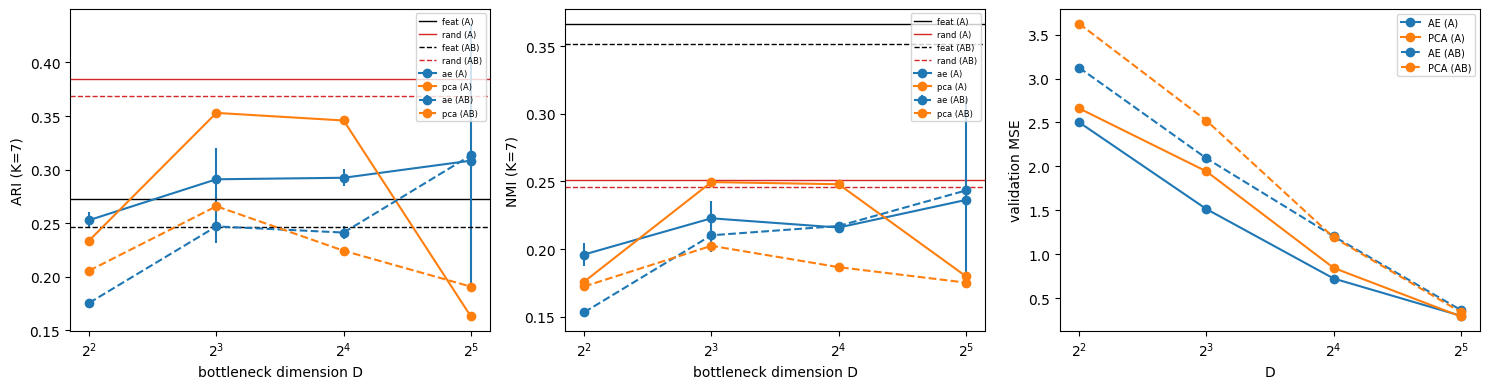

In [25]:
k7 = CL_DF[CL_DF.K == KS[0]]; fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, met in zip(ax[:2], ("ARI", "NMI")):
    for pool, ls in zip(POOLS, ("-", "--")):
        for fam, col in (("ae", "C0"), ("pca", "C1")):
            s = k7[(k7.pool == pool) & (k7.fam == fam)].groupby("dim")[met].agg(["mean", "std"])
            a.errorbar(s.index, s["mean"], s["std"].fillna(0), color=col, ls=ls, marker="o", label=f"{fam} ({pool})")
        for fam, col in (("feat", "k"), ("rand", "C3")):
            v = k7[(k7.pool == pool) & (k7.fam == fam)][met].mean(); a.axhline(v, color=col, ls=ls, lw=1, label=f"{fam} ({pool})")
    a.set_xscale("log", base=2); a.set_xlabel("bottleneck dimension D"); a.set_ylabel(f"{met} (K={KS[0]})"); a.legend(fontsize=6)
for pool, ls in zip(POOLS, ("-", "--")):
    s = REC_DF[REC_DF.pool == pool].groupby("dim")[["ae_val_mse", "pca_val_mse"]].mean()
    ax[2].plot(s.index, s.ae_val_mse, "C0", ls=ls, marker="o", label=f"AE ({pool})")
    ax[2].plot(s.index, s.pca_val_mse, "C1", ls=ls, marker="o", label=f"PCA ({pool})")
ax[2].set_xscale("log", base=2); ax[2].set_xlabel("D"); ax[2].set_ylabel("validation MSE"); ax[2].legend(fontsize=7)
fig.tight_layout(); fig.savefig(OUT / "fig" / "e1_bottleneck_sweep.png", dpi=200); plt.show()


## Bottleneck size
Cluster agreement does not increase consistently with $D$. For the
autoencoder, ARI and NMI rise slowly from $D=4$ to $D=32$, and the seed
variability is large at $D=32$ for $U_{AB}$. PCA peaks at $D=8$--$16$ and
falls at $D=32$, but it was fitted once, so this pattern may be noise.
In both measures the best trained embeddings stay at or below the untrained
encoder (ARI) and the hand-crafted features (NMI), and $U_{AB}$ is below
$U_A$ for almost every setting. Reconstruction error, in contrast, falls
steadily with $D$, and the autoencoder lies below PCA at small $D$ and
coincides with it from $D=16$--$32$. Better reconstruction therefore does not
translate into clusters that match behaviour.

---------------------------------------

 ## E2: probe score vs amount of labelled data

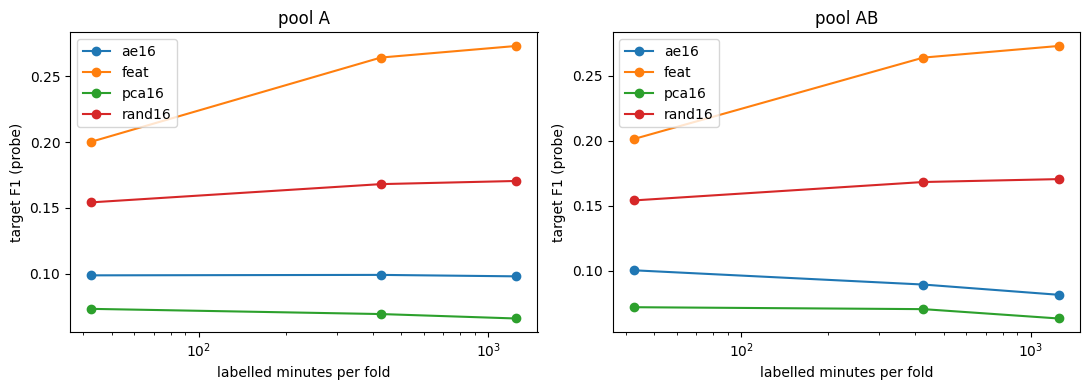

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, pool in zip(ax, POOLS[:2]):
    for rep in sorted(PROBE_REPS):
        s = PR_DF[(PR_DF.pool == pool) & (PR_DF.rep == rep)].groupby("frac")[["minutes", "target"]].mean()
        if len(s): a.plot(s.minutes, s.target, marker="o", label=rep)
    a.set_xscale("log"); a.set_xlabel("labelled minutes per fold"); a.set_ylabel("target F1 (probe)"); a.set_title(f"pool {pool}"); a.legend()
fig.tight_layout(); fig.savefig(OUT / "fig" / "e2_probe_label_efficiency.png", dpi=200); plt.show()


## Label efficiency
Only the hand-crafted features benefit from more labelled data, rising from
0.20 to 0.27 as the labelled data grow from about 43 to 1\,250 minutes.
The untrained encoder improves slightly (0.15 to 0.17), and the autoencoder
and PCA embeddings stay flat at about 0.10 and 0.07, i.e.\ below the untrained
encoder at every label budget. For $U_{AB}$ the autoencoder declines further
with more labels (to about 0.08). Extra labels therefore cannot compensate for
information the representation has discarded, and the ordering of the
representations is the same for both pools.

--------------------------------------- 

# 9. Pool check (E4): is logger B different from A and from the labelled data?

 Uses the autoencoder (D=16, seed 0) trained on A+B, and the hand-crafted features.

 * Reconstruction error by source and by behaviour: where does the autoencoder struggle?

 * Domain classifier: can a classifier tell two sources apart? AUC 0.5 = cannot, 1.0 = always.

In [27]:
ae_rep, feat_rep = KEEP[POOLS[-1]]; rng = np.random.RandomState(7)
src = {"A": sample_segments(["A"], N_DOM, rng), "B": sample_segments(["B"], N_DOM, rng)}
li = rng.choice(len(XL), min(N_DOM, len(XL)), replace=False); src["L"] = (XL[li], np.array(["L"] * len(li)), rL[li])

rec = {s: float(recon_mse(ae_rep, v[0]).mean()) for s, v in src.items()}
print("Reconstruction error by source:", {k: round(v, 4) for k, v in rec.items()})
cls_err = pd.Series(recon_mse(ae_rep, XL[li])).groupby(pd.Series(yL[li]).map(dict(enumerate(CLASS_NAMES)))).mean().sort_values()
print("Reconstruction error by behaviour class (labelled segments):"); print(cls_err.round(4).to_string())


Reconstruction error by source: {'A': 1.0462, 'B': 1.7627, 'L': 1.3551}
Reconstruction error by behaviour class (labelled segments):
Resting       0.1194
Gliding       0.7126
Feeding       0.8252
Scratching    1.4164
Swimming      1.4169
Other         4.0630
Breathing     8.6972


## Reconstruction error by source and class
The mean reconstruction error is highest for the logger~B windows (1.76),
lower for the labelled data (1.36) and lowest for logger~A (1.05).
Across classes, error is lowest for Resting (0.12) and highest for Breathing
(8.7) and \emph{Other} (4.1); the target classes lie in between (Gliding 0.71,
Feeding 0.83, Scratching 1.42). The error is therefore not ordered by
behavioural relevance. A plausible but untested explanation is that the
squared error is dominated by large-amplitude events, so that the capacity of
the autoencoder is spent on them rather than on the subtler patterns of the target
classes.

---------------------------------------

In [28]:
def domain_auc(a, b):
    """Can a classifier tell source a from source b? Cross-validated by recording."""
    n = min(len(a[0]), len(b[0])); X = np.vstack([a[0][:n], b[0][:n]]); y = np.r_[np.zeros(n), np.ones(n)]
    grp = np.r_[a[1][:n], b[1][:n]]
    p = cross_val_predict(GradientBoostingClassifier(n_estimators=100, random_state=0), X, y, groups=grp,
                          cv=GroupKFold(min(5, len(np.unique(grp)))), method="predict_proba")[:, 1]
    return roc_auc_score(y, p)

dom = []
for a, b in (("A", "B"), ("L", "A"), ("L", "B")):
    dom.append({"pair": f"{a} vs {b}",
                **{r.name: domain_auc((r(src[a][0]), src[a][2]), (r(src[b][0]), src[b][2])) for r in (ae_rep, feat_rep)}})
DOM_DF = pd.DataFrame(dom); print("Domain-classifier AUC:"); print(DOM_DF.round(3).to_string()); DOM_DF.to_csv(OUT / "domain_auc.csv", index=False)


Domain-classifier AUC:
     pair   ae16   feat
0  A vs B  0.550  0.924
1  L vs A  0.432  0.695
2  L vs B  0.591  0.867


## Domain gap
A classifier on the autoencoder embedding barely separates the sources (AUC
0.43--0.59, close to chance), whereas one on the hand-crafted features separates
logger~B from both logger~A (0.92) and the labelled data (0.87). Labelled and
logger~A data are separated less (0.70). Logger~B thus differs systematically
in its signal statistics, in agreement with its higher reconstruction error, but
the autoencoder embedding does not encode this difference. Windows from $U_B$
should therefore be used with caution as sources of pseudo-labels. The AUC below
0.5 (0.43) reflects sampling noise.

---------------------------

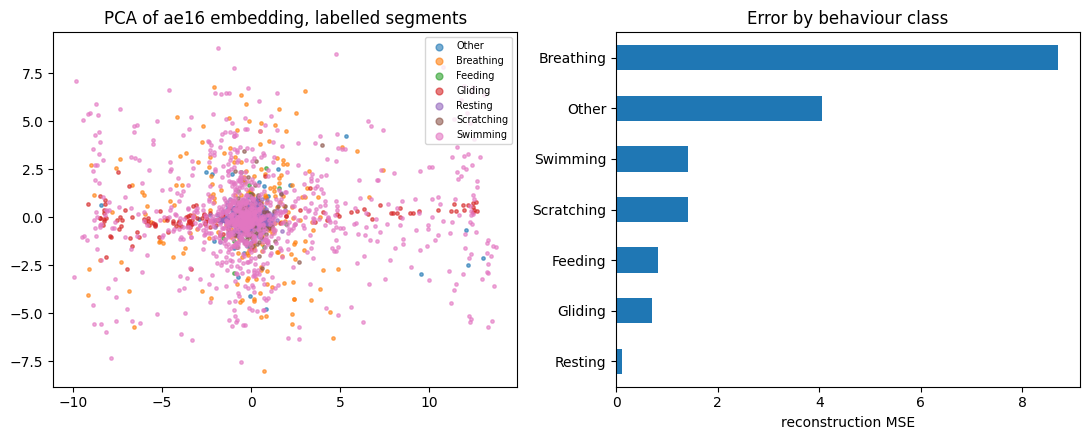

outputs in Model_results\EXPLORATORY_unsupervised


In [29]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5)); Zs = PCA(2).fit_transform(ae_rep(XL[li])); cols = plt.cm.tab10(np.arange(NC))
for c in range(NC): ax[0].scatter(*Zs[yL[li] == c].T, s=6, color=cols[c], label=CLASS_NAMES[c], alpha=.6)
ax[0].set_title(f"PCA of ae{PROBE_DIM} embedding, labelled segments"); ax[0].legend(fontsize=7, markerscale=2)
cls_err.plot.barh(ax=ax[1]); ax[1].set_xlabel("reconstruction MSE"); ax[1].set_title("Error by behaviour class")
fig.tight_layout(); fig.savefig(OUT / "fig" / "e4_embedding_and_error.png", dpi=200); plt.show()
print("outputs in", OUT)


## Embedding
In the two-dimensional PCA projection of the 16-dimensional embedding
(Figure~\ref{fig:e4}), the classes overlap strongly and most windows, largely
Swimming, form a dense central cloud. Gliding spreads along the first component,
but no class forms a separate cluster. This agrees with the low ARI/NMI and
the weak probe scores: the embedding has no visible behavioural structure,
at least in its first two components.

---------------------------------------

### Overall, a trained autoencoder gives no benefit over an untrained one, hand-crafted features are the best label-free representation, and label-free clusters cannot recover the target classes.